# Crop Yield Prediction Using Machine Learning

**Case Study 29 — ML Fundamentals Semester Project**  
**Dataset:** Agriculture Precision Study Cases — Modern Agriculture AI Crop Production 2020–2050  
**Objective:** Predict `yield_ton_per_ha` from agricultural and climatic features.

---

## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Paths
DATA_PATH    = '../data/modern_agriculture_ai_crop_production_2020_2050.csv'
RESULTS_DIR  = '../results'
MODELS_DIR   = '../models'

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR,  exist_ok=True)

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print('Setup complete.')

Setup complete.


## 2. Load & Inspect the Dataset

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f'Shape: {df_raw.shape}')
print(f'Columns ({len(df_raw.columns)}):')
for c in df_raw.columns:
    print(f'  {c}: {df_raw[c].dtype}')

Shape: (75000, 36)
Columns (36):
  record_id: int64
  year: int64
  region: object
  country: object
  crop: object
  farm_size_hectares: float64
  farm_type: object
  soil_type: object
  irrigation_type: object
  ai_system_used: object
  technology_stack: object
  ai_adoption_score: float64
  mechanization_index: float64
  iot_sensor_density_per_ha: float64
  drone_usage_hours_per_month: float64
  satellite_monitoring_score: float64
  avg_temperature_c: float64
  annual_rainfall_mm: float64
  soil_moisture_percent: float64
  fertilizer_kg_per_ha: float64
  pesticide_litre_per_ha: float64
  water_use_m3_per_ha: float64
  climate_stress_index: float64
  disease_risk_score: float64
  pest_risk_score: float64
  yield_ton_per_ha: float64
  production_tons: float64
  operational_cost_usd_per_ha: float64
  market_price_usd_per_ton: float64
  revenue_usd: float64
  profit_usd: float64
  carbon_emission_kgco2e_per_ha: float64
  sustainability_score: float64
  yield_forecast_next_year_ton_per_h

In [3]:
df_raw.head()

,record_id,year,region,country,crop,farm_size_hectares,farm_type,soil_type,irrigation_type,ai_system_used,...,production_tons,operational_cost_usd_per_ha,market_price_usd_per_ton,revenue_usd,profit_usd,carbon_emission_kgco2e_per_ha,sustainability_score,yield_forecast_next_year_ton_per_ha,risk_category,recommended_action
0,1,2035,South America,Chile,Dates,40.78,Semi-Mechanized,Peaty,Rainfed,NaN,...,330.32,1059.23,196.12,64782.36,21586.96,646.75,54.25,8.38,Moderate,Start with IoT soil sensors and basic AI analy...
1,2,2038,Middle East,Turkey,Potato,17.04,Traditional,Silty,Smart Drip,NaN,...,422.59,1017.69,442.65,187059.46,169718.02,948.05,28.77,24.56,Moderate,Start with IoT soil sensors and basic AI analy...
2,3,2036,Africa,Egypt,Mango,119.06,Smart AI Farm,Loam,Drip,AI Irrigation Agent,...,1382.29,1479.36,463.90,641244.33,465111.73,1062.54,57.07,11.81,Moderate,Maintain current smart farming plan
3,4,2031,Europe,Germany,Rice,23.15,Semi-Mechanized,Silty,Flood Irrigation,Yield Prediction ML,...,126.86,1088.85,375.24,47602.95,22396.07,672.48,54.67,5.60,Moderate,Shift to drip or smart irrigation
4,5,2029,South America,Colombia,Sugarcane,22.03,Semi-Mechanized,Silty,Drip,Basic Analytics,...,1441.42,870.99,198.97,286799.34,267611.43,516.42,44.15,72.07,Moderate,Deploy pest monitoring traps and precision spr...


In [4]:
print('=== Basic Statistics (Selected Numerical Columns) ===')
relevant_num = [
    'avg_temperature_c','annual_rainfall_mm','fertilizer_kg_per_ha',
    'pesticide_litre_per_ha','soil_moisture_percent','climate_stress_index',
    'yield_ton_per_ha'
]
df_raw[relevant_num].describe().round(2)

=== Basic Statistics (Selected Numerical Columns) ===


,avg_temperature_c,annual_rainfall_mm,fertilizer_kg_per_ha,pesticide_litre_per_ha,soil_moisture_percent,climate_stress_index,yield_ton_per_ha
count,75000.00,75000.00,75000.00,75000.00,75000.00,75000.00,75000.00
mean,27.00,651.02,135.26,2.41,36.83,46.82,17.14
std,5.50,275.63,54.15,1.08,11.19,15.25,21.34
min,7.67,50.00,15.00,0.10,5.00,0.00,1.07
25%,23.14,460.94,98.04,1.66,29.25,36.14,3.59
50%,26.97,648.14,134.94,2.40,36.80,45.68,6.26
75%,30.76,836.00,171.61,3.14,44.39,56.44,25.50
max,46.92,1906.85,360.00,6.85,87.50,100.00,105.91


In [5]:
print('=== Missing Values ===')
miss = df_raw.isnull().sum()
print(miss[miss > 0] if miss.sum() > 0 else 'No missing values in selected features.')
print(f'\nTotal rows: {len(df_raw)}')
print(f'Missing only in: ai_system_used (not a selected feature — excluded)')

=== Missing Values ===
ai_system_used    14981
dtype: int64

Total rows: 75000
Missing only in: ai_system_used (not a selected feature — excluded)


### Feature Selection

The dataset has 36 columns. We keep only features that are:
1. **Agronomic inputs** available before harvest (no leakage).
2. **Predictive** of yield (supported by correlation analysis).

**Excluded columns and reasons:**
- `record_id`, `year`: identifiers, not predictive features.
- `country`: too granular — region already captures geography.
- `farm_size_hectares`: uncorrelated with yield rate (tons/ha).
- `ai_system_used`: 20% missing; not a core agronomic input.
- `technology_stack`, `ai_adoption_score`, `mechanization_index`, `iot_sensor_density_per_ha`, `drone_usage_hours_per_month`, `satellite_monitoring_score`: AI/tech columns — outside the scope of Case Study 29.
- `water_use_m3_per_ha`: derived post-irrigation, potential leakage.
- `production_tons`: = yield × farm_size (direct leakage).
- `market_price_usd_per_ton`, `revenue_usd`, `profit_usd`, `operational_cost_usd_per_ha`: financial outcomes, post-harvest leakage.
- `yield_forecast_next_year_ton_per_ha`: correlation=0.998 with target — direct leakage.
- `carbon_emission_kgco2e_per_ha`, `sustainability_score`: consequence of farming, not inputs.
- `risk_category`, `recommended_action`: categorical labels derived from yield — leakage.

**Selected Features:**

In [6]:
# Numerical features (agronomic / environmental inputs)
NUM_FEATURES = [
    'avg_temperature_c',        # Average seasonal temperature
    'annual_rainfall_mm',       # Total annual rainfall
    'fertilizer_kg_per_ha',     # Fertilizer applied
    'pesticide_litre_per_ha',   # Pesticide applied
    'soil_moisture_percent',    # Soil moisture at measurement time
    'climate_stress_index',     # Composite climate stress score (drought/heat)
]

# Nominal categorical features — OneHotEncoded
CAT_FEATURES = [
    'crop',             # Crop variety
    'soil_type',        # Soil texture
    'irrigation_type',  # Irrigation method
    'region',           # Geographic zone
    'farm_type',        # Farming technology level
]

TARGET = 'yield_ton_per_ha'

ALL_FEATURES = NUM_FEATURES + CAT_FEATURES
df = df_raw[ALL_FEATURES + [TARGET]].copy()

print(f'Working dataframe: {df.shape}')
print(f'Features ({len(ALL_FEATURES)}): {ALL_FEATURES}')
print(f'Target: {TARGET}')
print(f'Missing values in working set:')
print(df.isnull().sum())

Working dataframe: (75000, 12)
Features (11): ['avg_temperature_c', 'annual_rainfall_mm', 'fertilizer_kg_per_ha', 'pesticide_litre_per_ha', 'soil_moisture_percent', 'climate_stress_index', 'crop', 'soil_type', 'irrigation_type', 'region', 'farm_type']
Target: yield_ton_per_ha
Missing values in working set:
avg_temperature_c         0
annual_rainfall_mm        0
fertilizer_kg_per_ha      0
pesticide_litre_per_ha    0
soil_moisture_percent     0
climate_stress_index      0
crop                      0
soil_type                 0
irrigation_type           0
region                    0
farm_type                 0
yield_ton_per_ha          0
dtype: int64


## 3. Exploratory Data Analysis (EDA)

### 3.1 Target Variable: Yield Distribution

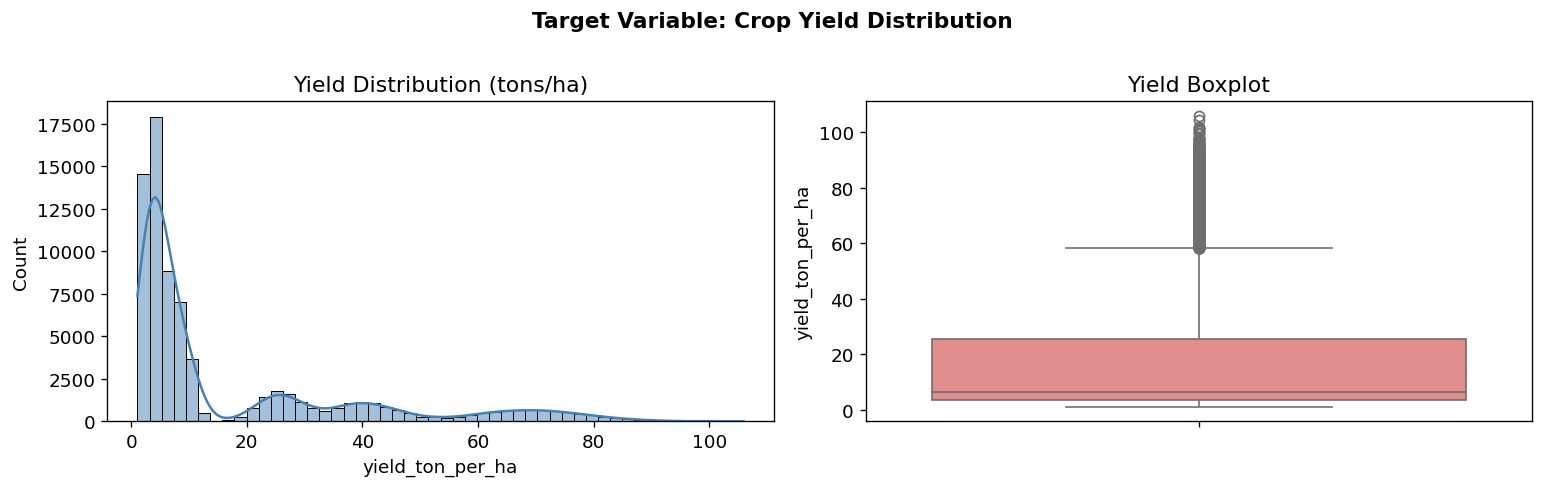

Mean: 17.14 | Std: 21.34
Min: 1.07 | Max: 105.91

Note: The bimodal/multi-modal distribution reflects different crop varieties (e.g., Sugarcane ~70 t/ha, Wheat ~3.6 t/ha).


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df[TARGET], bins=50, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Yield Distribution (tons/ha)')
axes[0].set_xlabel('yield_ton_per_ha')

sns.boxplot(y=df[TARGET], color='lightcoral', ax=axes[1])
axes[1].set_title('Yield Boxplot')
axes[1].set_ylabel('yield_ton_per_ha')

plt.suptitle('Target Variable: Crop Yield Distribution', y=1.01, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/01_yield_distribution.png', bbox_inches='tight')
plt.show()

print(f'Mean: {df[TARGET].mean():.2f} | Std: {df[TARGET].std():.2f}')
print(f'Min: {df[TARGET].min():.2f} | Max: {df[TARGET].max():.2f}')
print('\nNote: The bimodal/multi-modal distribution reflects different crop varieties (e.g., Sugarcane ~70 t/ha, Wheat ~3.6 t/ha).')

### 3.2 Yield by Crop Type

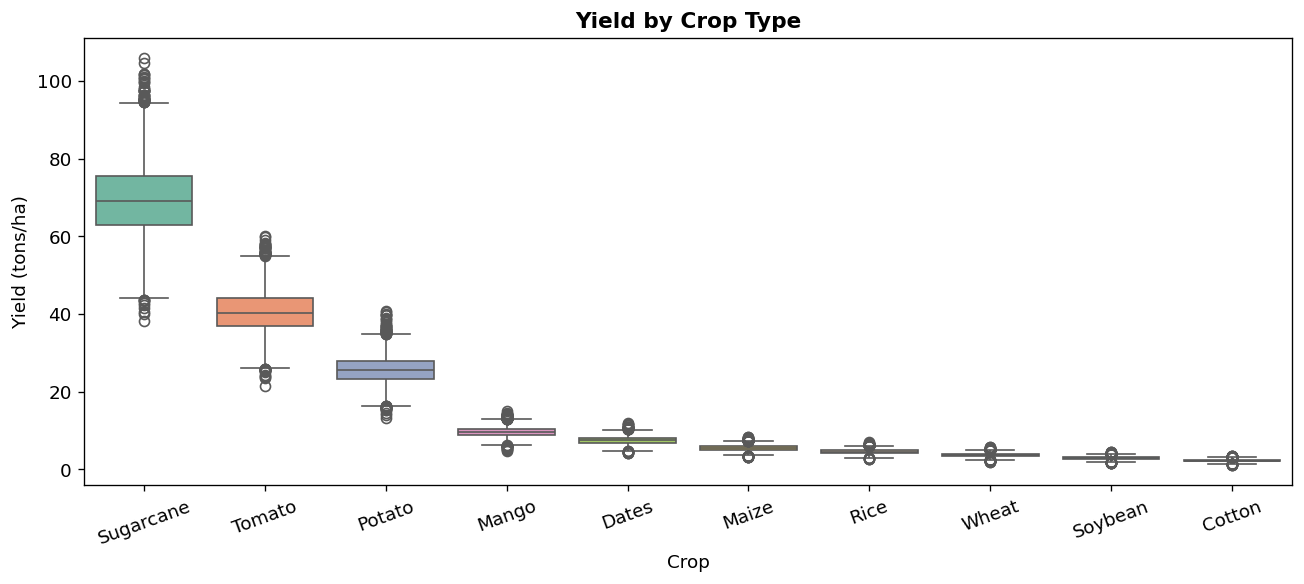

            mean   std    min     max
crop                                 
Sugarcane  69.35  9.26  38.10  105.91
Tomato     40.46  5.40  21.53   60.17
Potato     25.59  3.44  13.25   40.66
Mango       9.57  1.29   4.79   15.01
Dates       7.45  1.02   4.09   12.00
Maize       5.43  0.72   3.17    8.24
Rice        4.48  0.59   2.61    6.98
Wheat       3.63  0.49   1.79    5.75
Soybean     2.88  0.39   1.69    4.41
Cotton      2.24  0.30   1.07    3.37

Key finding: Crop type is the dominant predictor. Sugarcane (~69 t/ha) and Tomato (~40 t/ha) greatly exceed grains (Wheat ~3.6 t/ha).


In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
order = df.groupby('crop')[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='crop', y=TARGET, order=order, palette='Set2', ax=ax)
ax.set_title('Yield by Crop Type', fontsize=13, fontweight='bold')
ax.set_xlabel('Crop')
ax.set_ylabel('Yield (tons/ha)')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/02_yield_by_crop.png', bbox_inches='tight')
plt.show()

crop_stats = df.groupby('crop')[TARGET].agg(['mean','std','min','max']).round(2)
print(crop_stats.sort_values('mean', ascending=False))
print('\nKey finding: Crop type is the dominant predictor. Sugarcane (~69 t/ha) and Tomato (~40 t/ha) greatly exceed grains (Wheat ~3.6 t/ha).')

### 3.3 Correlation Heatmap (Numerical Features)

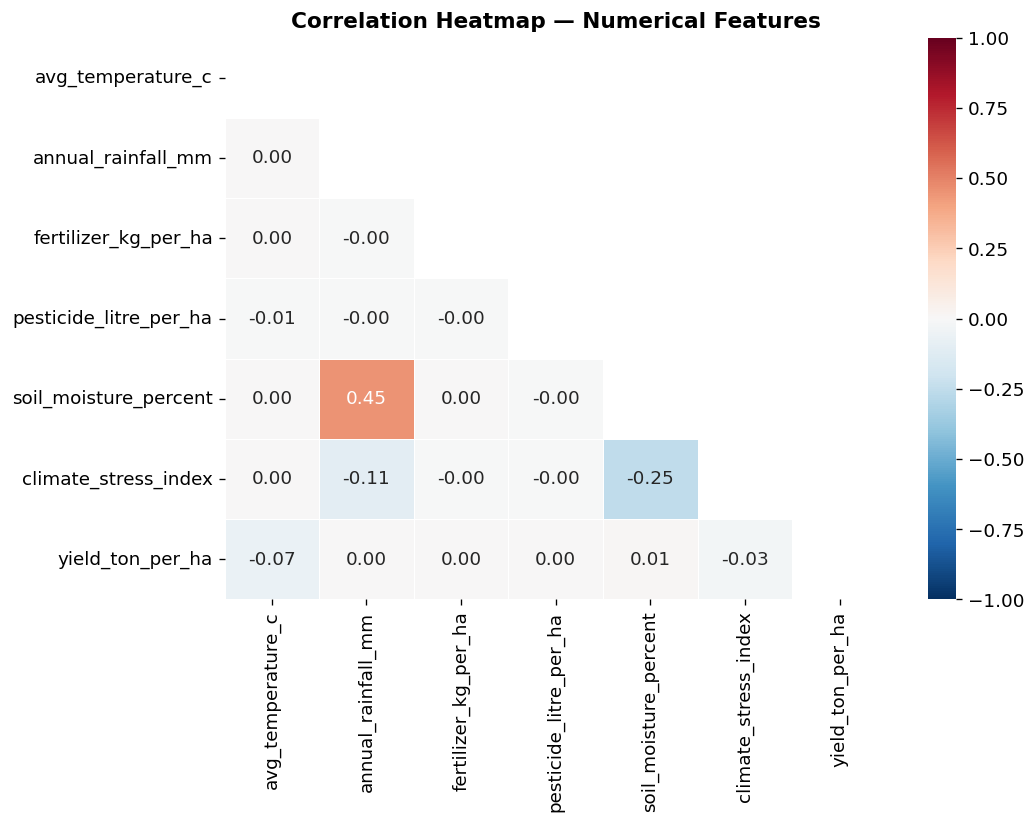

Correlation of each numerical feature with yield:
soil_moisture_percent     0.0094
annual_rainfall_mm        0.0033
fertilizer_kg_per_ha      0.0018
pesticide_litre_per_ha    0.0008
climate_stress_index     -0.0275
avg_temperature_c        -0.0687

Note: Low individual correlations are expected because crop type (categorical) dominates yield — numerical features have within-crop predictive value.


In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
corr_matrix = df[NUM_FEATURES + [TARGET]].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            ax=ax, linewidths=0.5)
ax.set_title('Correlation Heatmap — Numerical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/03_correlation_heatmap.png', bbox_inches='tight')
plt.show()

print('Correlation of each numerical feature with yield:')
print(corr_matrix[TARGET].drop(TARGET).sort_values(ascending=False).round(4).to_string())
print('\nNote: Low individual correlations are expected because crop type (categorical) dominates yield — numerical features have within-crop predictive value.')

### 3.4 Rainfall vs Yield

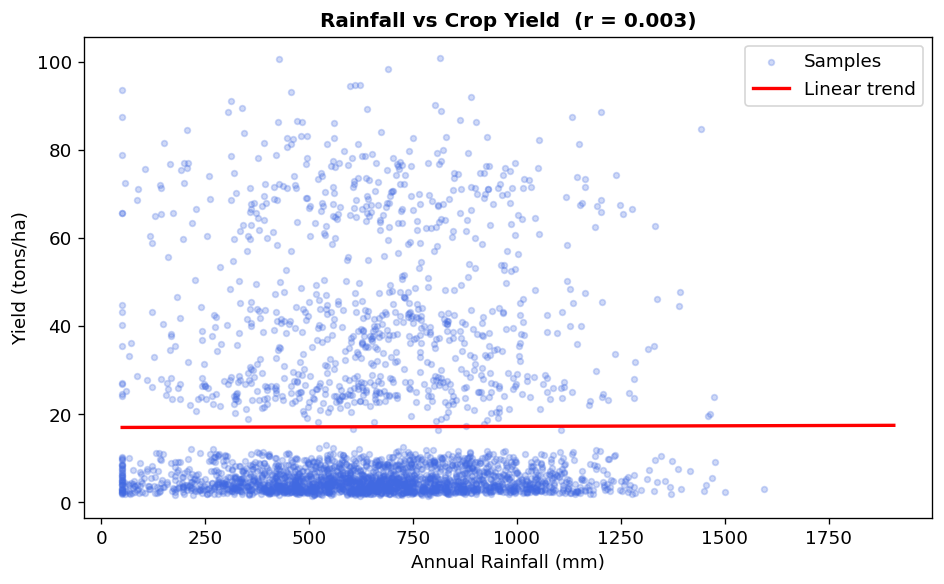

Pearson correlation (rainfall vs yield): 0.0033
The near-zero overall correlation is because crop variety differences dominate. Rainfall effects are visible within each crop.


In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sample = df.sample(3000, random_state=42)
ax.scatter(sample['annual_rainfall_mm'], sample[TARGET],
           alpha=0.25, s=12, color='royalblue', label='Samples')

# linear trend
z = np.polyfit(df['annual_rainfall_mm'], df[TARGET], 1)
x_line = np.linspace(df['annual_rainfall_mm'].min(), df['annual_rainfall_mm'].max(), 200)
ax.plot(x_line, np.polyval(z, x_line), 'r-', linewidth=2, label='Linear trend')

r = df['annual_rainfall_mm'].corr(df[TARGET])
ax.set_xlabel('Annual Rainfall (mm)')
ax.set_ylabel('Yield (tons/ha)')
ax.set_title(f'Rainfall vs Crop Yield  (r = {r:.3f})', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/04_rainfall_vs_yield.png', bbox_inches='tight')
plt.show()

print(f'Pearson correlation (rainfall vs yield): {r:.4f}')
print('The near-zero overall correlation is because crop variety differences dominate. Rainfall effects are visible within each crop.')

### 3.5 Temperature vs Yield

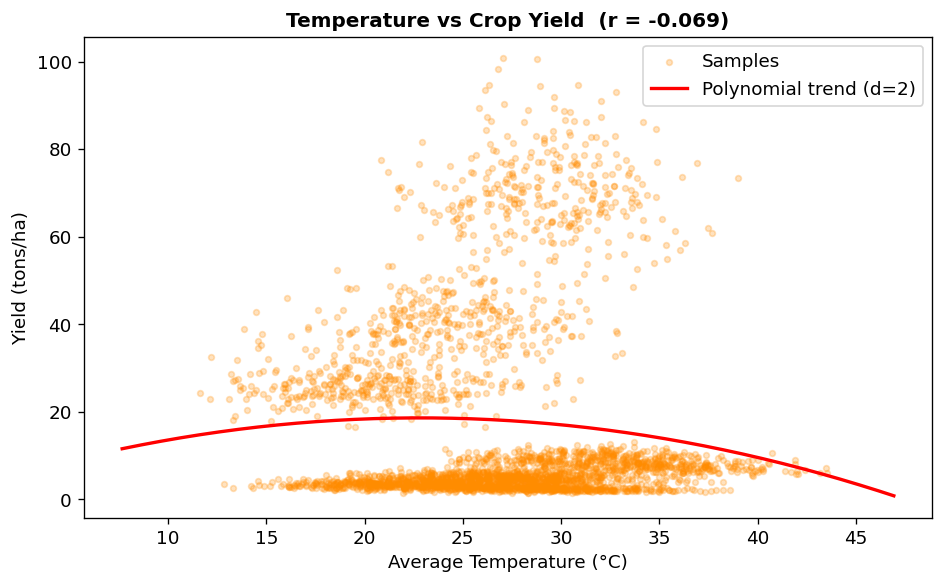

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample['avg_temperature_c'], sample[TARGET],
           alpha=0.25, s=12, color='darkorange', label='Samples')

# Polynomial (degree 2) trend to look for concavity
z2 = np.polyfit(df['avg_temperature_c'], df[TARGET], 2)
x_t = np.linspace(df['avg_temperature_c'].min(), df['avg_temperature_c'].max(), 200)
ax.plot(x_t, np.polyval(z2, x_t), 'r-', linewidth=2, label='Polynomial trend (d=2)')

r = df['avg_temperature_c'].corr(df[TARGET])
ax.set_xlabel('Average Temperature (°C)')
ax.set_ylabel('Yield (tons/ha)')
ax.set_title(f'Temperature vs Crop Yield  (r = {r:.3f})', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/05_temperature_vs_yield.png', bbox_inches='tight')
plt.show()

### 3.6 Fertilizer vs Yield — Linear vs Polynomial Fit

**Requirement of Case Study 29:** Investigate whether the relationship between fertilizer and yield is linear or nonlinear.

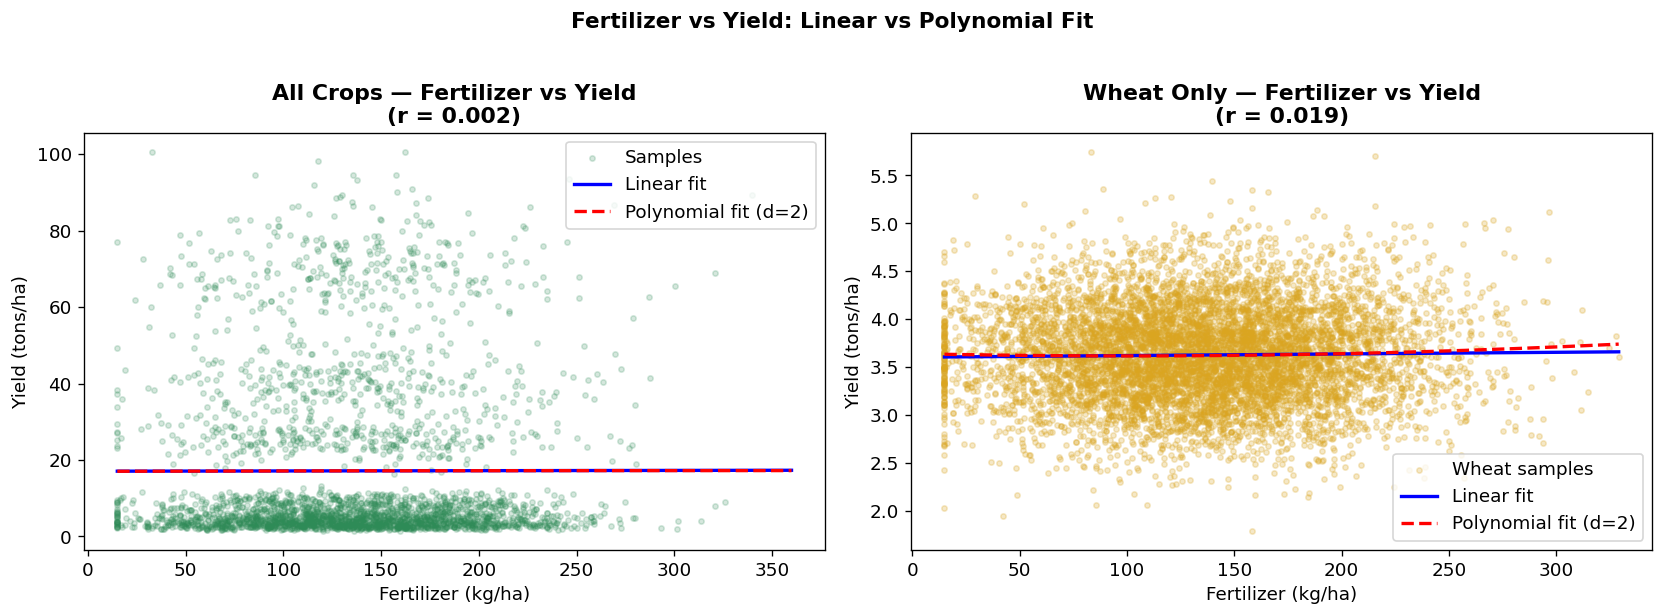

=== Fertilizer Analysis ===
Overall (all crops) — Pearson r: 0.0018
Within Wheat only — Pearson r: 0.0189

Finding: In this dataset, the fertilizer-yield relationship is approximately FLAT/RANDOM.
Both linear and polynomial fits are nearly horizontal.
The dataset simulates a global mix of crops and farming conditions where fertilizer application
is not the primary driver of yield differences — crop variety is dominant.
This is a data-driven conclusion, not a forced result.

Despite the weak overall correlation, Polynomial Regression is still included
because: (1) it is a required algorithm, (2) it can capture any latent curvature,
and (3) serves as a comparison point against linear baseline and ensemble models.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fert = df['fertilizer_kg_per_ha']
yld  = df[TARGET]
x_f  = np.linspace(fert.min(), fert.max(), 300)

# Left: full dataset
axes[0].scatter(sample['fertilizer_kg_per_ha'], sample[TARGET],
                alpha=0.2, s=10, color='seagreen', label='Samples')
z1 = np.polyfit(fert, yld, 1)
z2 = np.polyfit(fert, yld, 2)
axes[0].plot(x_f, np.polyval(z1, x_f), 'b-', linewidth=2, label='Linear fit')
axes[0].plot(x_f, np.polyval(z2, x_f), 'r--', linewidth=2, label='Polynomial fit (d=2)')
r_all = fert.corr(yld)
axes[0].set_title(f'All Crops — Fertilizer vs Yield\n(r = {r_all:.3f})', fontweight='bold')
axes[0].set_xlabel('Fertilizer (kg/ha)')
axes[0].set_ylabel('Yield (tons/ha)')
axes[0].legend()

# Right: within a single crop (Wheat) to see agronomic signal
wheat = df[df['crop'] == 'Wheat']
axes[1].scatter(wheat['fertilizer_kg_per_ha'], wheat[TARGET],
                alpha=0.25, s=10, color='goldenrod', label='Wheat samples')
z1w = np.polyfit(wheat['fertilizer_kg_per_ha'], wheat[TARGET], 1)
z2w = np.polyfit(wheat['fertilizer_kg_per_ha'], wheat[TARGET], 2)
x_fw = np.linspace(wheat['fertilizer_kg_per_ha'].min(), wheat['fertilizer_kg_per_ha'].max(), 200)
axes[1].plot(x_fw, np.polyval(z1w, x_fw), 'b-', linewidth=2, label='Linear fit')
axes[1].plot(x_fw, np.polyval(z2w, x_fw), 'r--', linewidth=2, label='Polynomial fit (d=2)')
r_wheat = wheat['fertilizer_kg_per_ha'].corr(wheat[TARGET])
axes[1].set_title(f'Wheat Only — Fertilizer vs Yield\n(r = {r_wheat:.3f})', fontweight='bold')
axes[1].set_xlabel('Fertilizer (kg/ha)')
axes[1].set_ylabel('Yield (tons/ha)')
axes[1].legend()

plt.suptitle('Fertilizer vs Yield: Linear vs Polynomial Fit', y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/06_fertilizer_vs_yield_fit.png', bbox_inches='tight')
plt.show()

print('=== Fertilizer Analysis ===')
print(f'Overall (all crops) — Pearson r: {r_all:.4f}')
print(f'Within Wheat only — Pearson r: {r_wheat:.4f}')
print()
print('Finding: In this dataset, the fertilizer-yield relationship is approximately FLAT/RANDOM.')
print('Both linear and polynomial fits are nearly horizontal.')
print('The dataset simulates a global mix of crops and farming conditions where fertilizer application')
print('is not the primary driver of yield differences — crop variety is dominant.')
print('This is a data-driven conclusion, not a forced result.')
print()
print('Despite the weak overall correlation, Polynomial Regression is still included')
print('because: (1) it is a required algorithm, (2) it can capture any latent curvature,')
print('and (3) serves as a comparison point against linear baseline and ensemble models.')

### 3.7 Pesticide vs Yield

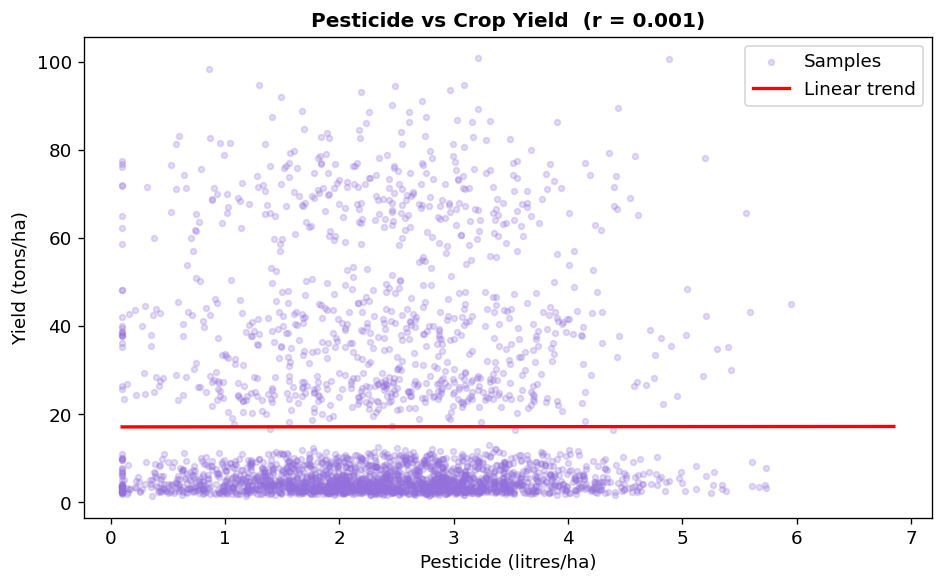

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample['pesticide_litre_per_ha'], sample[TARGET],
           alpha=0.25, s=12, color='mediumpurple', label='Samples')
z1p = np.polyfit(df['pesticide_litre_per_ha'], df[TARGET], 1)
x_p = np.linspace(df['pesticide_litre_per_ha'].min(), df['pesticide_litre_per_ha'].max(), 200)
ax.plot(x_p, np.polyval(z1p, x_p), 'r-', linewidth=2, label='Linear trend')
r_p = df['pesticide_litre_per_ha'].corr(df[TARGET])
ax.set_xlabel('Pesticide (litres/ha)')
ax.set_ylabel('Yield (tons/ha)')
ax.set_title(f'Pesticide vs Crop Yield  (r = {r_p:.3f})', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/07_pesticide_vs_yield.png', bbox_inches='tight')
plt.show()

### 3.8 Climate Stress Index vs Yield

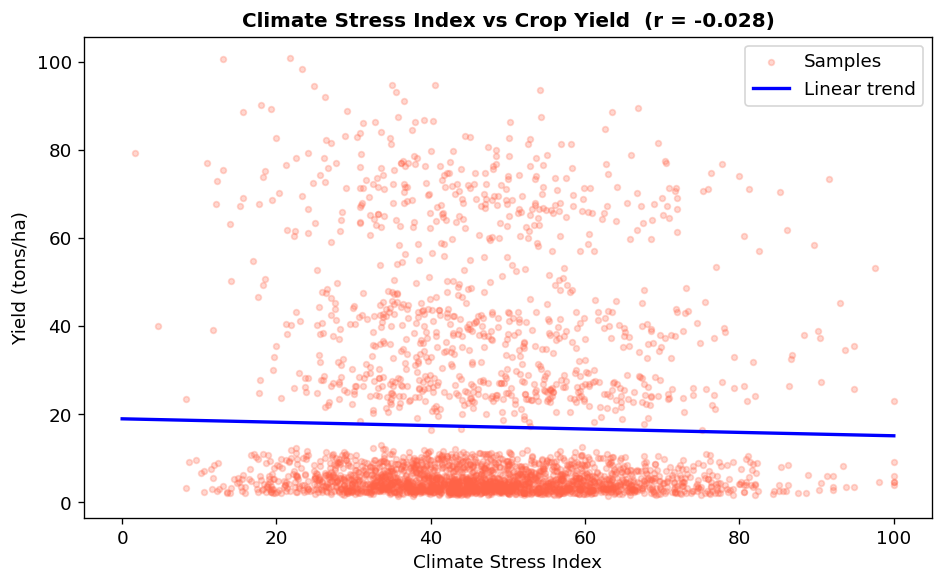

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample['climate_stress_index'], sample[TARGET],
           alpha=0.25, s=12, color='tomato', label='Samples')
z1c = np.polyfit(df['climate_stress_index'], df[TARGET], 1)
x_c = np.linspace(df['climate_stress_index'].min(), df['climate_stress_index'].max(), 200)
ax.plot(x_c, np.polyval(z1c, x_c), 'b-', linewidth=2, label='Linear trend')
r_c = df['climate_stress_index'].corr(df[TARGET])
ax.set_xlabel('Climate Stress Index')
ax.set_ylabel('Yield (tons/ha)')
ax.set_title(f'Climate Stress Index vs Crop Yield  (r = {r_c:.3f})', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/08_climate_stress_vs_yield.png', bbox_inches='tight')
plt.show()

### 3.9 Yield by Soil Type & Irrigation Type

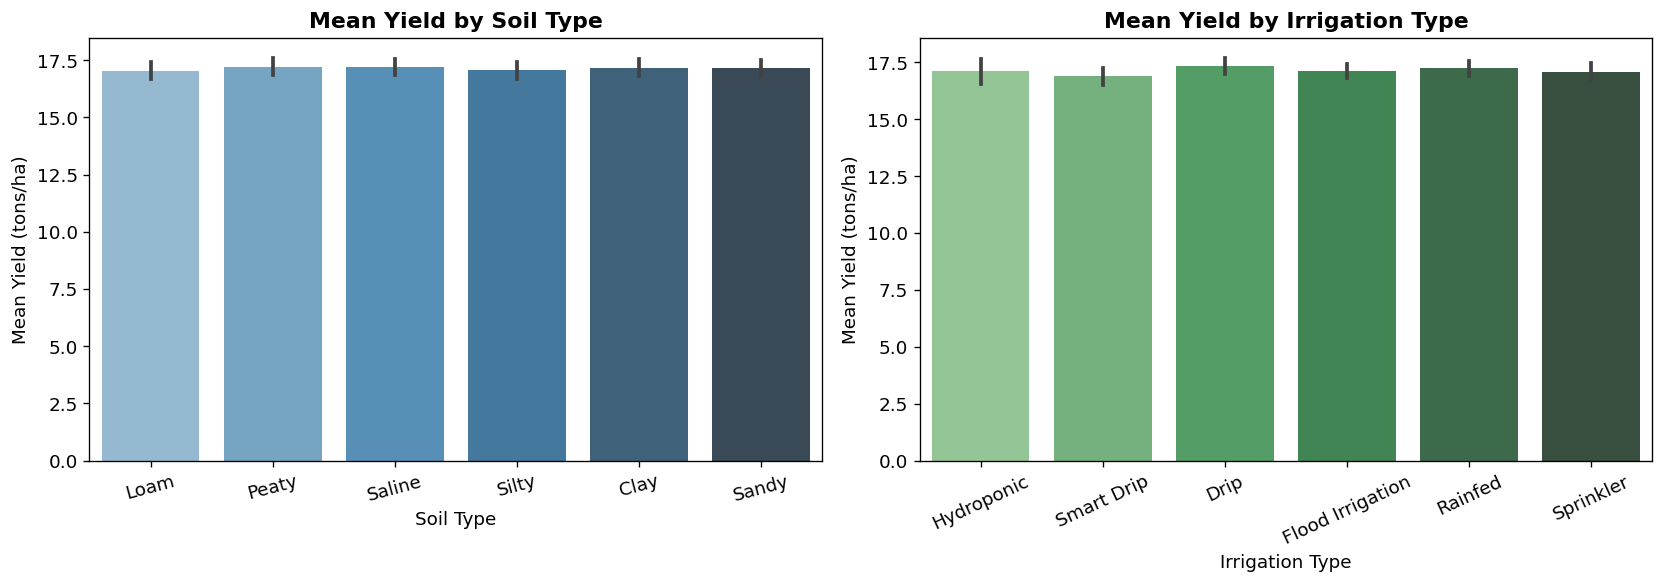

Note: Yield differences across soil type and irrigation type are minimal (~same mean)
because crop variety largely determines the yield range in this global dataset.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

soil_order = df.groupby('soil_type')[TARGET].median().sort_values(ascending=False).index
sns.barplot(data=df, x='soil_type', y=TARGET, order=soil_order, palette='Blues_d', ax=axes[0])
axes[0].set_title('Mean Yield by Soil Type', fontweight='bold')
axes[0].set_xlabel('Soil Type')
axes[0].set_ylabel('Mean Yield (tons/ha)')
axes[0].tick_params(axis='x', rotation=15)

irr_order = df.groupby('irrigation_type')[TARGET].median().sort_values(ascending=False).index
sns.barplot(data=df, x='irrigation_type', y=TARGET, order=irr_order, palette='Greens_d', ax=axes[1])
axes[1].set_title('Mean Yield by Irrigation Type', fontweight='bold')
axes[1].set_xlabel('Irrigation Type')
axes[1].set_ylabel('Mean Yield (tons/ha)')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/09_categorical_vs_yield.png', bbox_inches='tight')
plt.show()

print('Note: Yield differences across soil type and irrigation type are minimal (~same mean)')
print('because crop variety largely determines the yield range in this global dataset.')

## 4. Preprocessing Pipeline

All preprocessing is fitted **only on training data** to prevent leakage.

- **Numerical:** `SimpleImputer(median)` (no missing in selected features, but safeguard) then passed through.
- **Categorical:** `SimpleImputer(most_frequent)` + `OneHotEncoder(handle_unknown='ignore')` — preserves true nominal nature; no artificial ordering like LabelEncoder would impose.

In [16]:
X = df[ALL_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set:  {X_train.shape}')
print(f'Test set:      {X_test.shape}')

# Preprocessing transformers
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, NUM_FEATURES),
    ('cat', cat_transformer, CAT_FEATURES),
])

print('\nPreprocessor built. Columns used:')
print(f'  Numerical ({len(NUM_FEATURES)}): {NUM_FEATURES}')
print(f'  Categorical ({len(CAT_FEATURES)}): {CAT_FEATURES}')

Training set:  (60000, 11)
Test set:      (15000, 11)

Preprocessor built. Columns used:
  Numerical (6): ['avg_temperature_c', 'annual_rainfall_mm', 'fertilizer_kg_per_ha', 'pesticide_litre_per_ha', 'soil_moisture_percent', 'climate_stress_index']
  Categorical (5): ['crop', 'soil_type', 'irrigation_type', 'region', 'farm_type']


## 5. Model Training & Evaluation

All five required models are trained as **scikit-learn Pipelines** that include the preprocessor.
This ensures the exact same transformation is applied at inference time.

In [17]:
def evaluate(name, pipeline, X_tr, y_tr, X_te, y_te):
    """Fit a pipeline, compute test metrics and 5-fold CV R²."""
    pipeline.fit(X_tr, y_tr)
    preds = pipeline.predict(X_te)

    r2   = r2_score(y_te, preds)
    mse  = mean_squared_error(y_te, preds)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_te, preds)

    cv_scores = cross_val_score(pipeline, X_tr, y_tr, cv=5, scoring='r2')

    print(f'{name:40s}  R²={r2:.4f}  RMSE={rmse:.4f}  CV={cv_scores.mean():.4f}±{cv_scores.std():.4f}')

    return {
        'Model':        name,
        'R²':           round(r2,   4),
        'MSE':          round(mse,  4),
        'RMSE':         round(rmse, 4),
        'MAE':          round(mae,  4),
        '5-Fold CV R²': f'{cv_scores.mean():.4f} ± {cv_scores.std():.4f}',
    }, preds, pipeline

In [18]:
results   = []
all_preds = {}
all_pipes = {}

# ── 1. Linear Regression ────────────────────────────────────────────────────
# What: Ordinary Least Squares — fits a straight-line combination of features.
# Why baseline: Simplest possible model; if complex models don't beat it
#               significantly, the relationships may be approximately linear.
lr_pipe = Pipeline([('pre', preprocessor), ('model', LinearRegression())])
res, preds, pipe = evaluate('Linear Regression', lr_pipe, X_train, y_train, X_test, y_test)
results.append(res); all_preds['Linear Regression'] = preds; all_pipes['Linear Regression'] = pipe

# ── 2. Polynomial Regression (degree 2) ─────────────────────────────────────
# What: Adds squared and cross-product terms to capture non-linear relationships.
# Why: Useful for detecting curvature in fertilizer-vs-yield and interactions
#      between temperature, rainfall, and stress.
# Note: Polynomial features are added AFTER OHE (on numeric columns only via scaled step)
num_poly = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
    ('poly',    PolynomialFeatures(degree=2, include_bias=False)),
])
cat_transformer2 = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor_poly = ColumnTransformer([
    ('num', num_poly, NUM_FEATURES),
    ('cat', cat_transformer2, CAT_FEATURES),
])
poly_pipe = Pipeline([('pre', preprocessor_poly), ('model', LinearRegression())])
res, preds, pipe = evaluate('Polynomial Regression (d=2)', poly_pipe, X_train, y_train, X_test, y_test)
results.append(res); all_preds['Polynomial Regression (d=2)'] = preds; all_pipes['Polynomial Regression (d=2)'] = pipe

# ── 3. Decision Tree ─────────────────────────────────────────────────────────
# What: Recursive binary splits on feature values. Naturally handles non-linearity.
# Why: Useful for detecting discrete crop-type boundaries and interaction thresholds.
# Limitation: Prone to overfitting without depth control — we set max_depth=10.
dt_pipe = Pipeline([('pre', preprocessor), ('model', DecisionTreeRegressor(max_depth=10, random_state=42))])
res, preds, pipe = evaluate('Decision Tree', dt_pipe, X_train, y_train, X_test, y_test)
results.append(res); all_preds['Decision Tree'] = preds; all_pipes['Decision Tree'] = pipe

# ── 4. Random Forest ─────────────────────────────────────────────────────────
# What: Ensemble of 100 decision trees trained on bootstrap samples.
# Why: Reduces the variance of Decision Tree via averaging; captures complex
#      interactions between crop, climate, and soil features.
rf_pipe = Pipeline([('pre', preprocessor), ('model', RandomForestRegressor(
    n_estimators=100, max_depth=15, random_state=42, n_jobs=-1))])
res, preds, pipe = evaluate('Random Forest', rf_pipe, X_train, y_train, X_test, y_test)
results.append(res); all_preds['Random Forest'] = preds; all_pipes['Random Forest'] = pipe

# ── 5. Gradient Boosting ─────────────────────────────────────────────────────
# What: Sequential ensemble where each tree corrects the residual errors of previous trees.
# Why: Typically the strongest regressor for tabular data with mixed feature types.
#      The sequential correction is particularly useful for the high-yield-variance
#      crop types in this dataset.
gb_pipe = Pipeline([('pre', preprocessor), ('model', GradientBoostingRegressor(
    n_estimators=150, learning_rate=0.1, max_depth=6, random_state=42))])
res, preds, pipe = evaluate('Gradient Boosting', gb_pipe, X_train, y_train, X_test, y_test)
results.append(res); all_preds['Gradient Boosting'] = preds; all_pipes['Gradient Boosting'] = pipe

Linear Regression                         R²=0.9710  RMSE=3.6345  CV=0.9723±0.0004


Polynomial Regression (d=2)               R²=0.9710  RMSE=3.6348  CV=0.9723±0.0004


Decision Tree                             R²=0.9672  RMSE=3.8649  CV=0.9683±0.0003


Random Forest                             R²=0.9717  RMSE=3.5901  CV=0.9727±0.0005


Gradient Boosting                         R²=0.9716  RMSE=3.5929  CV=0.9726±0.0005


## 6. Model Comparison

In [19]:
results_df = pd.DataFrame(results).sort_values('R²', ascending=False).reset_index(drop=True)
results_df.insert(0, 'Rank', range(1, len(results_df) + 1))
results_df.loc[0, 'Model'] = '🥇 ' + str(results_df.loc[0, 'Model'])

print('=== Final Model Comparison Table ===')
print(results_df.to_string(index=False))

results_df.to_csv(f'{RESULTS_DIR}/model_comparison.csv', index=False)
print('\nSaved to results/model_comparison.csv')

=== Final Model Comparison Table ===
 Rank                       Model     R²     MSE   RMSE    MAE    5-Fold CV R²
    1             🥇 Random Forest 0.9717 12.8888 3.5901 1.7960 0.9727 ± 0.0005
    2           Gradient Boosting 0.9716 12.9090 3.5929 1.7993 0.9726 ± 0.0005
    3           Linear Regression 0.9710 13.2094 3.6345 1.9023 0.9723 ± 0.0004
    4 Polynomial Regression (d=2) 0.9710 13.2119 3.6348 1.9029 0.9723 ± 0.0004
    5               Decision Tree 0.9672 14.9374 3.8649 1.8976 0.9683 ± 0.0003

Saved to results/model_comparison.csv


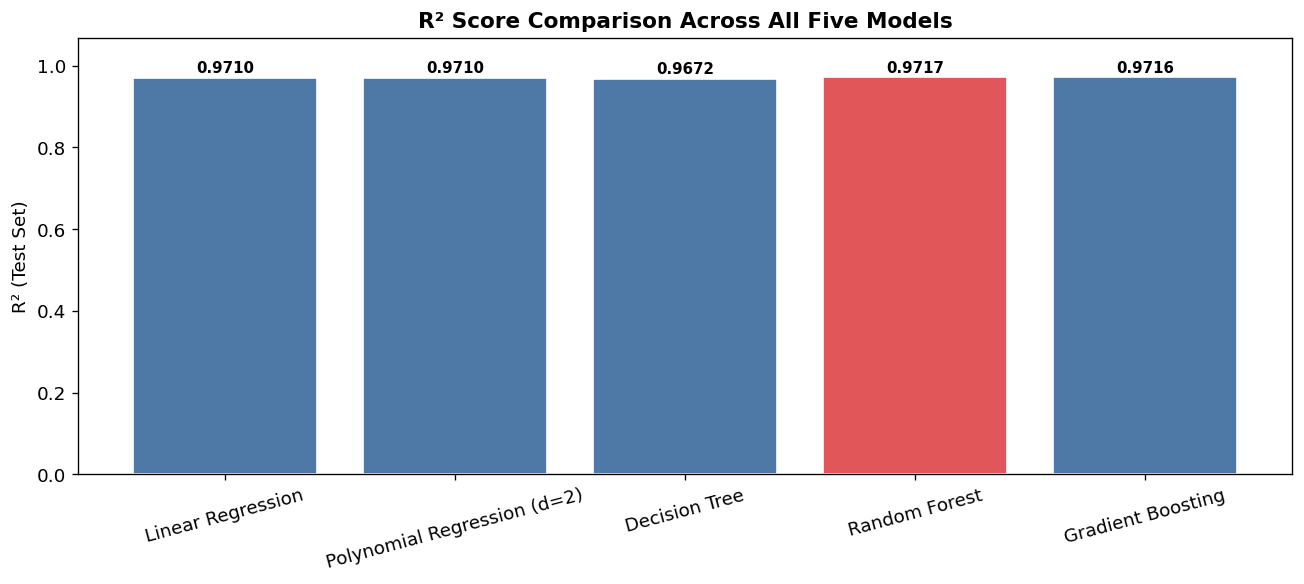

In [20]:
# Bar chart: R² comparison
model_names = [r['Model'] for r in results]
r2_values   = [r['R²']   for r in results]

colors = ['#e15759' if v == max(r2_values) else '#4e79a7' for v in r2_values]
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(model_names, r2_values, color=colors, edgecolor='white')
ax.set_title('R² Score Comparison Across All Five Models', fontsize=13, fontweight='bold')
ax.set_ylabel('R² (Test Set)')
ax.set_ylim(0, max(r2_values) * 1.1)
for bar, v in zip(bars, r2_values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{v:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/10_r2_comparison.png', bbox_inches='tight')
plt.show()

## 7. Best Model — Actual vs Predicted & Residual Analysis

Best model (by R²): Random Forest


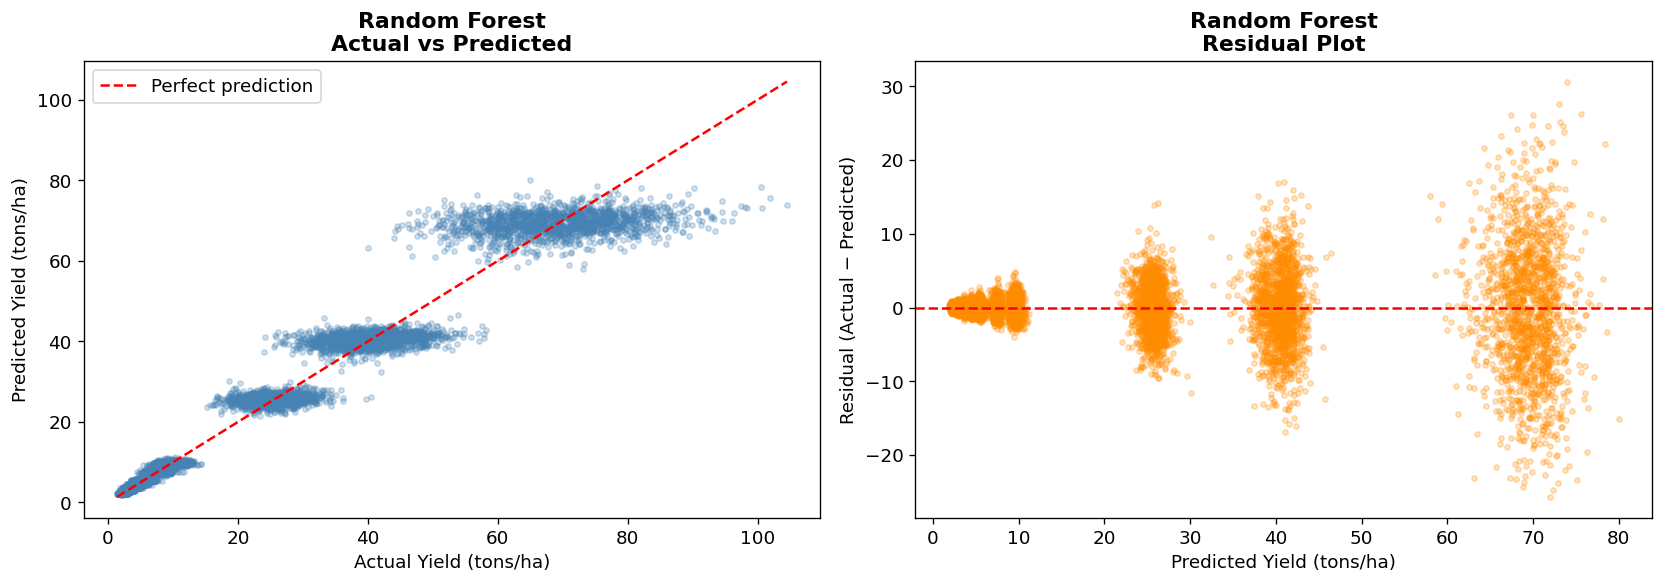


Residual statistics:
  Mean: -0.0502  (close to 0 → unbiased)
  Std:  3.5897  (= RMSE of best model)
  Max error: 30.6185 tons/ha


In [21]:
# Identify best model from actual results
best_name = results_df.loc[0, 'Model'].replace('🥇 ', '')
best_preds = all_preds[best_name]
best_pipe  = all_pipes[best_name]

print(f'Best model (by R²): {best_name}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, best_preds, alpha=0.25, s=10, color='steelblue')
lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual Yield (tons/ha)')
axes[0].set_ylabel('Predicted Yield (tons/ha)')
axes[0].set_title(f'{best_name}\nActual vs Predicted', fontweight='bold')
axes[0].legend()

# Residuals
residuals = y_test.values - best_preds
axes[1].scatter(best_preds, residuals, alpha=0.25, s=10, color='darkorange')
axes[1].axhline(0, color='red', linewidth=1.5, linestyle='--')
axes[1].set_xlabel('Predicted Yield (tons/ha)')
axes[1].set_ylabel('Residual (Actual − Predicted)')
axes[1].set_title(f'{best_name}\nResidual Plot', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/11_actual_vs_predicted_residuals.png', bbox_inches='tight')
plt.show()

print(f'\nResidual statistics:')
print(f'  Mean: {residuals.mean():.4f}  (close to 0 → unbiased)')
print(f'  Std:  {residuals.std():.4f}  (= RMSE of best model)')
print(f'  Max error: {np.abs(residuals).max():.4f} tons/ha')

## 8. Actual vs Predicted — All Five Models

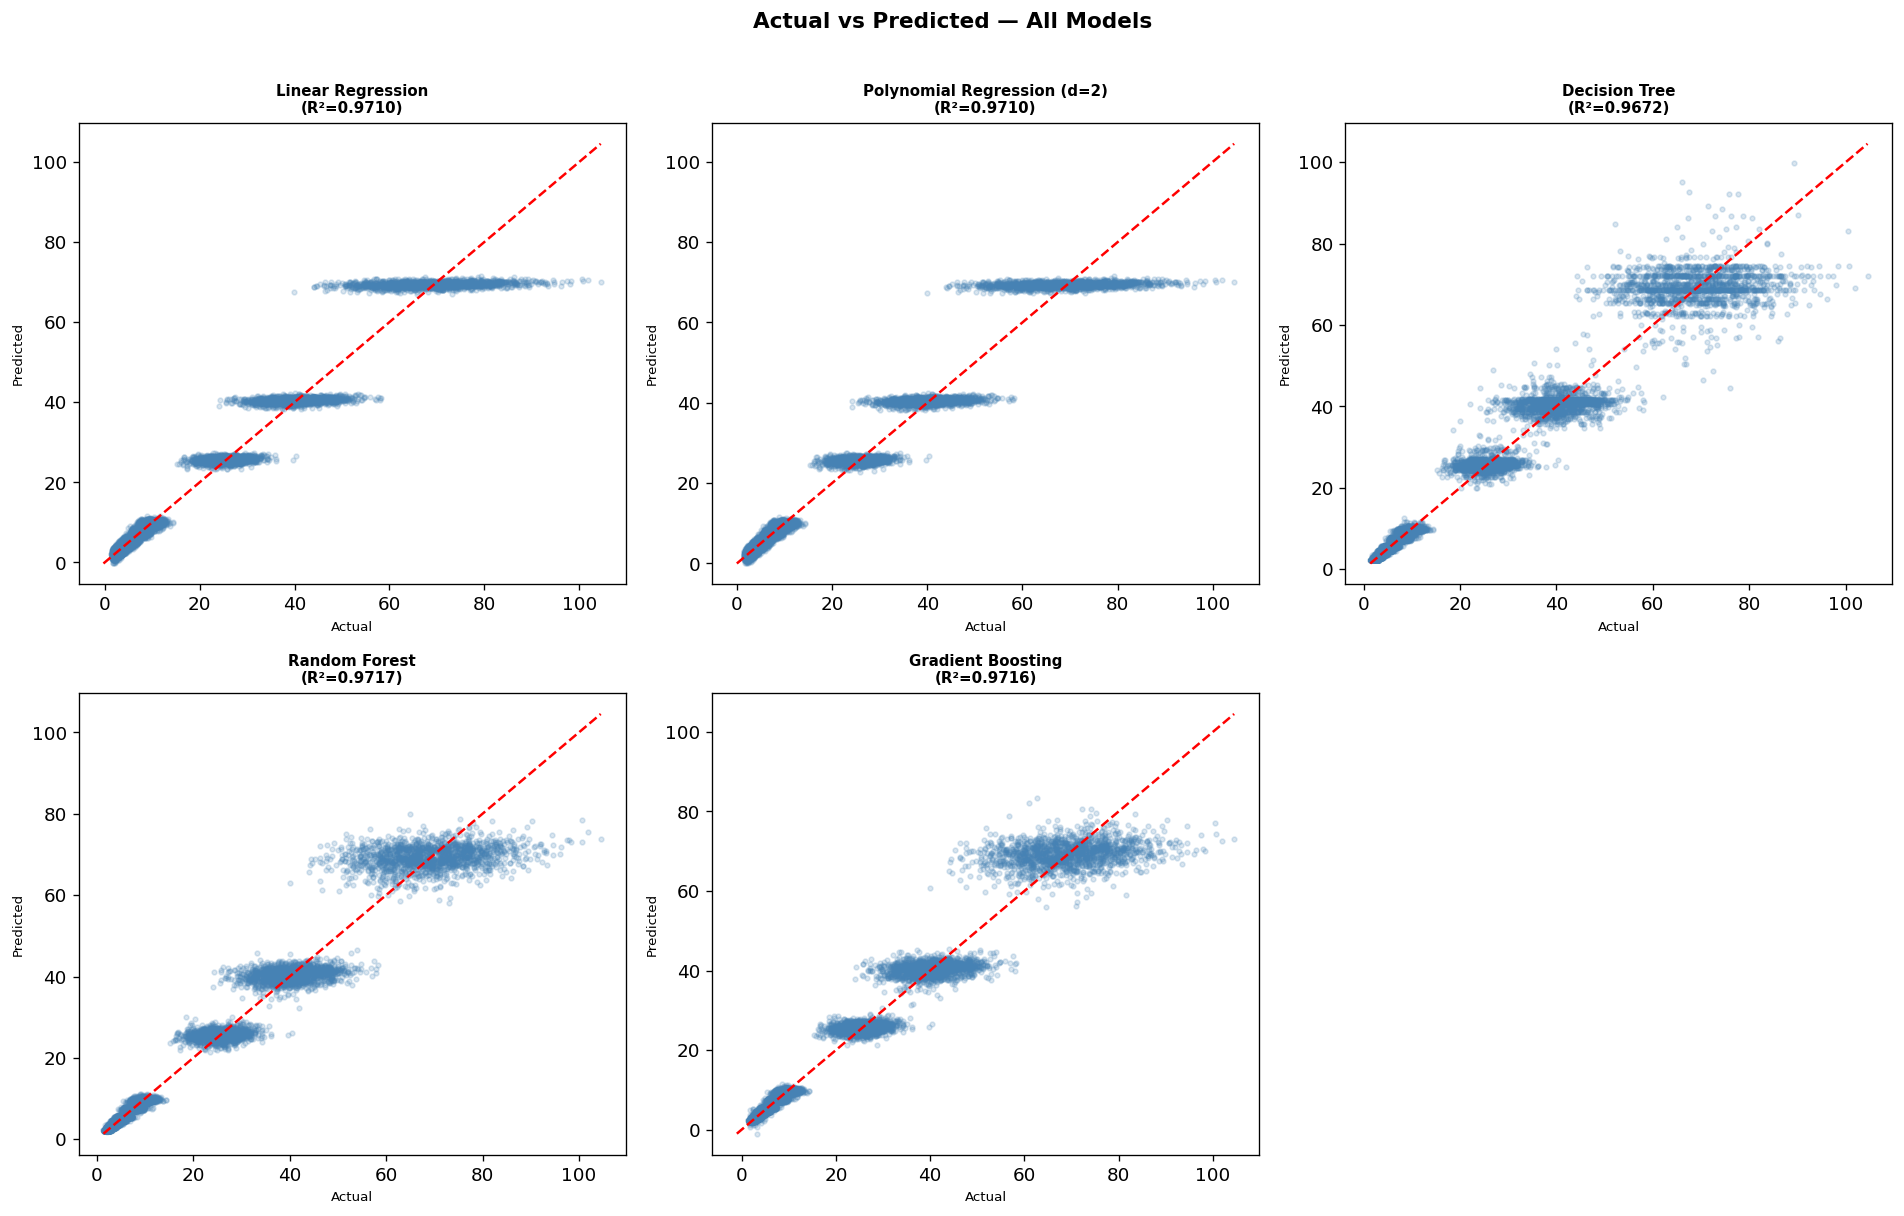

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, preds) in enumerate(all_preds.items()):
    ax = axes[i]
    ax.scatter(y_test, preds, alpha=0.2, s=8, color='steelblue')
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5)
    r2 = r2_score(y_test, preds)
    ax.set_title(f'{name}\n(R²={r2:.4f})', fontsize=9, fontweight='bold')
    ax.set_xlabel('Actual', fontsize=8)
    ax.set_ylabel('Predicted', fontsize=8)

# hide unused subplot
axes[-1].set_visible(False)
plt.suptitle('Actual vs Predicted — All Models', y=1.01, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/12_all_models_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

## 9. Feature Importance (Tree-Based Models)

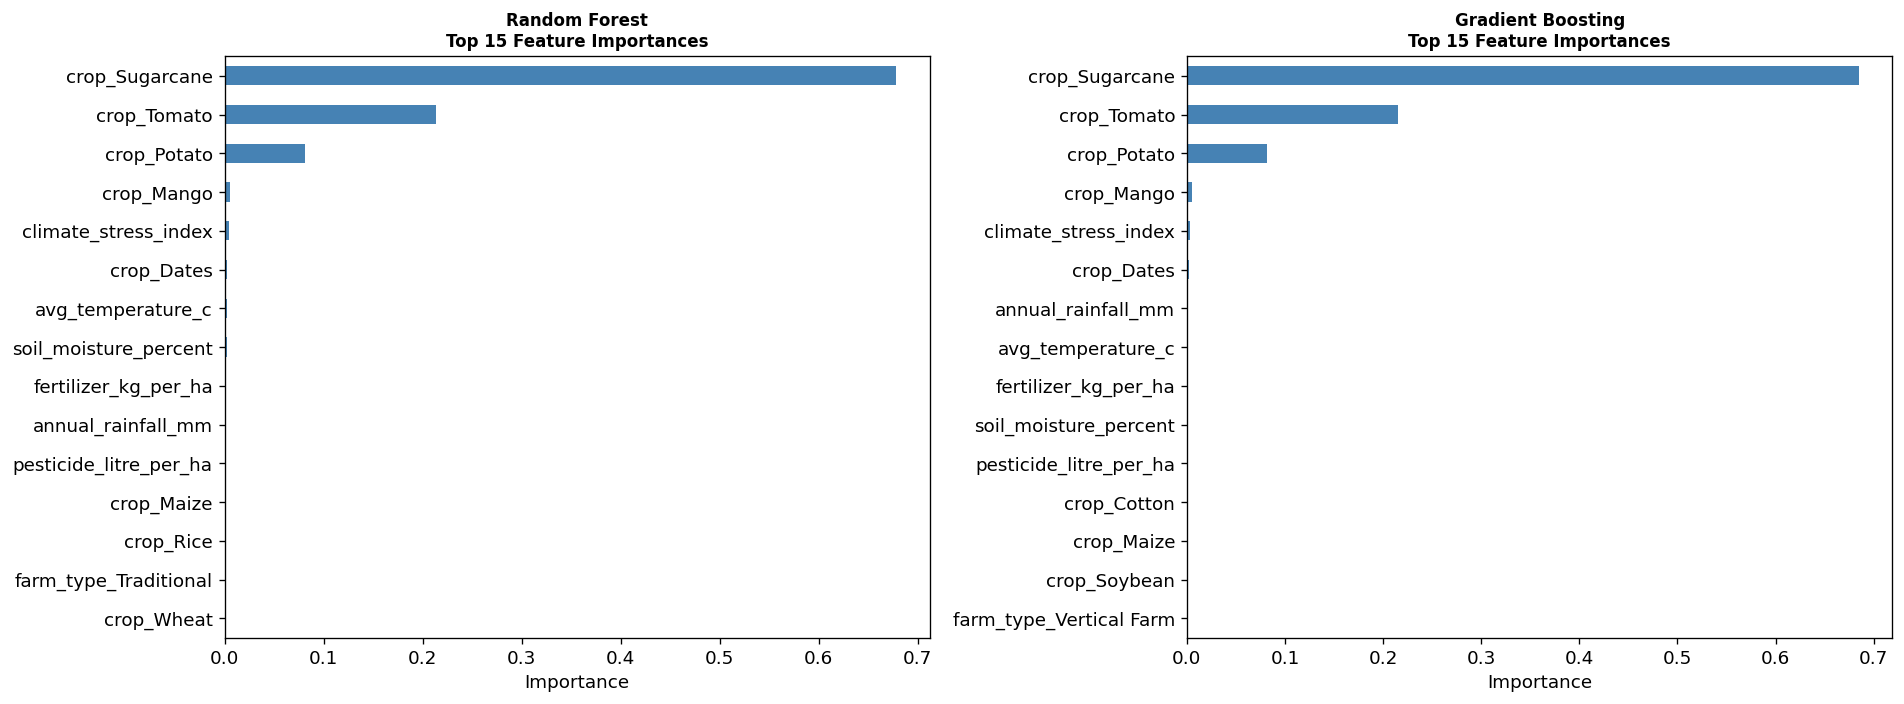

Note: Crop-type features dominate because yield ranges differ drastically between crops.
Climate stress index is the most important numerical feature within the context of individual crops.


In [23]:
def get_feature_names(pipe, num_feats, cat_feats):
    """Extract feature names after OHE from a pipeline."""
    pre = pipe.named_steps['pre']
    ohe = pre.named_transformers_['cat']
    if hasattr(ohe, 'named_steps'):
        ohe = ohe.named_steps.get('ohe', ohe)
    cat_names = list(ohe.get_feature_names_out(cat_feats))
    return num_feats + cat_names

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, name in zip(axes, ['Random Forest', 'Gradient Boosting']):
    pipe = all_pipes[name]
    model = pipe.named_steps['model']
    feat_names = get_feature_names(pipe, NUM_FEATURES, CAT_FEATURES)
    importances = pd.Series(model.feature_importances_, index=feat_names)
    top15 = importances.sort_values(ascending=False).head(15)

    top15.plot(kind='barh', ax=ax, color='steelblue')
    ax.invert_yaxis()
    ax.set_title(f'{name}\nTop 15 Feature Importances', fontweight='bold', fontsize=10)
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/13_feature_importance.png', bbox_inches='tight')
plt.show()
print('Note: Crop-type features dominate because yield ranges differ drastically between crops.')
print('Climate stress index is the most important numerical feature within the context of individual crops.')

## 10. Save Best Model Pipeline

In [24]:
best_row  = results_df.iloc[0]
best_name = best_row['Model'].replace('🥇 ', '')
best_pipeline = all_pipes[best_name]

print('=== Best Model Summary ===')
print(f'  Model  : {best_name}')
print(f'  R²     : {best_row["R²"]}')
print(f'  RMSE   : {best_row["RMSE"]} tons/ha')
print(f'  MAE    : {best_row["MAE"]} tons/ha')
print(f'  CV R²  : {best_row["5-Fold CV R²"]}')

# Save full pipeline (preprocessor + model)
save_path = f'{MODELS_DIR}/best_model.pkl'
joblib.dump({'pipeline': best_pipeline, 'model_name': best_name,
             'rmse': best_row['RMSE'], 'r2': best_row['R²'],
             'num_features': NUM_FEATURES, 'cat_features': CAT_FEATURES},
            save_path)
print(f'\nSaved pipeline to {save_path}')

# Sanity check: reload and predict
artifact = joblib.load(save_path)
sample_x = X_test.iloc[[0]]
pred_val  = artifact['pipeline'].predict(sample_x)[0]
actual    = y_test.iloc[0]
print(f'\nSanity check — Sample 0:')
print(f'  Predicted: {pred_val:.3f} tons/ha')
print(f'  Actual:    {actual:.3f} tons/ha')

=== Best Model Summary ===
  Model  : Random Forest
  R²     : 0.9717
  RMSE   : 3.5901 tons/ha
  MAE    : 1.796 tons/ha
  CV R²  : 0.9727 ± 0.0005

Saved pipeline to ../models/best_model.pkl



Sanity check — Sample 0:
  Predicted: 24.688 tons/ha
  Actual:    21.910 tons/ha
